# Shared DeepSet PPO — équilibre de Nash feedback de Salo & Tahvonen (2001)

**Idée** : le jeu est symétrique, donc on entraîne **un seul** couple actor/critic, équivariant par permutation (DeepSet), partagé par les $N$ joueurs :
$\hat\pi(q_i \mid x_i, \{x_j\}_{j\neq i})$ et $\hat V(x_i, \{x_j\}_{j\neq i})$. Chaque pas simulé fournit $N$ échantillons (un par joueur, avec sa propre récompense $F_i$).

- **Critic** : MSE sur les retours GAE + $\lambda_R\,\mathbb E[(R_i/\delta)^2]$, avec le résidu HJB exact
  $R_i = \delta \hat V_i - F_i(x,\hat q) - \nabla_x \hat V_i\cdot f(x,\hat q)$, $f=-\hat q$ (JVP, termes croisés inclus).
- **Actor** : PPO-clip + $\lambda_P\,\mathbb E[(\hat q_i - q_i^*)^2]/\delta$, avec $q_i^* = \arg\max_{q_i} H_i = \big(c x_i - \sum_{j\neq i}\hat q_j - \partial_{x_i}\hat V_i\big)/2$ (clippé), **cible détachée**.
- **Borne** : $\text{Nash\_Gap}(\hat\pi) \le \frac{2}{\delta}\sum_i\|R_i\|_\infty + \frac{1}{\delta}\sum_i\|P_i\|_\infty$, $P_i = H_i(q_i^*) - H_i(\hat q_i)$.

Code : package `DeepSet_PPO/` (`salo_game.py`, `deepset.py`, `residuals.py`, `shared_ppo.py`, `evaluation.py`).

In [1]:
import sys
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))   # DeepSet_PPO/ and Nash_Gap/ live in the parent dir

from DeepSet_PPO import (
    SaloGame, SaloReference, SharedPPOConfig, SharedPPOTrainer,
    hjb_residual, hamiltonian_gap, diag_gradient,
    rollout, deepset_policy_fn, evaluate, make_eval_fn,
)

## 1 — Paramètres (mêmes conditions que `salo_tahvonen_feedback.ipynb`)

In [2]:
# --- Game: c = 0.5, delta = 0.05, pbar = 10, dt = 0.1 ---
N_PLAYERS = 3
game = SaloGame(n_players=N_PLAYERS, c=0.5, delta=0.05, pbar=10.0, dt=0.1, q_max=2.0)

X0 = np.array([8.0, 5.0, 4.0])   # test initial stocks (Salo notebook)
EVAL_STEPS = 2000                # t_max = 200 -> e^{-delta t} ~ 4.5e-5

cfg = SharedPPOConfig(
    n_players_choices=(N_PLAYERS,),   # e.g. (2, 3, 5) to train on several N at once
    n_envs=64, rollout_len=256, episode_len=2000,
    x0_low=0.5, x0_high=10.0,         # covers X0
    iterations=500,
    lambda_hjb=1.0, lambda_mismatch=1.0, mismatch_warmup=50,
    entropy_coef=1e-3, hidden=64, x_scale=10.0, seed=0,
)
print("gamma per step =", game.gamma)

gamma per step = 0.9950124791926823


## 2 — Référence Salo & vérification des résidus

$V_i(x) = x^\top M_i x$ (Lyapunov, région intérieure où tous les $q_i>0$). Sur la solution exacte, $R_i$ et $P_i$ doivent être nuls : cela valide le code des résidus avant de l'utiliser comme loss.

In [3]:
ref = SaloReference(game)
print(f"mu1 = {ref.mu1:.6f}   mu2 = {ref.mu2:.6f}")

J_salo, X_salo, Q_salo = rollout(game, ref.policy, X0, EVAL_STEPS)
for i in range(N_PLAYERS):
    print(f"player {i}: x0 = {X0[i]:4.1f}   J_salo = {J_salo[i]:.4f}   x0^T M_i x0 = {X0 @ ref.M[i].numpy() @ X0:.4f}")

x = 0.5 + 9.5 * torch.rand(4096, N_PLAYERS)
x = x[ref.interior_mask(x)]
q = ref.policy(x)
R = hjb_residual(game, ref.value, x, q)
P, q_star = hamiltonian_gap(game, x, q, diag_gradient(ref.value, x))
print(f"\nSalo, interior states: max|R| = {R.abs().max():.2e}   max P = {P.max():.2e}   max|q*-q| = {(q_star - q).abs().max():.2e}")

mu1 = -0.022356   mu2 = 0.100439
player 0: x0 =  8.0   J_salo = 8.8599   x0^T M_i x0 = 8.7965
player 1: x0 =  5.0   J_salo = 2.6600   x0^T M_i x0 = 2.6449
player 2: x0 =  4.0   J_salo = 1.4323   x0^T M_i x0 = 1.4252

Salo, interior states: max|R| = 5.96e-07   max P = 4.77e-07   max|q*-q| = 3.58e-07


## 3 — Réseaux DeepSet partagés

In [4]:
trainer = SharedPPOTrainer(game, cfg)
actor, critic = trainer.actor, trainer.critic
print("actor params :", sum(p.numel() for p in actor.parameters()))
print("critic params:", sum(p.numel() for p in critic.parameters()))

# equivariance check: f(P x) = P f(x), for any N
xt = 10 * torch.rand(8, 5)
perm = torch.randperm(5)
print("equivariance error actor :", (actor(xt[:, perm]).mean - actor(xt).mean[:, perm]).abs().max().item())
print("equivariance error critic:", (critic(xt[:, perm]) - critic(xt)[:, perm]).abs().max().item())

actor params : 16962
critic params: 16897
equivariance error actor : 2.9802322387695312e-08
equivariance error critic: 1.4901161193847656e-08


## 4 — Entraînement

Toutes les `eval_every` itérations : $J_i$ de la politique déterministe depuis `X0` vs Salo, $(\mu_1,\mu_2)$ ajustés par moindres carrés sur $\hat q$, résidus et borne.

In [5]:
history = trainer.train(
    iterations=cfg.iterations,
    eval_fn=make_eval_fn(X0, steps=EVAL_STEPS, low=cfg.x0_low, high=cfg.x0_high),
    eval_every=25, log_every=25,
)

it    0 N=3 | ppo -0.001 ent -0.09 | vMSE 1.487e+00 hjb 1.382e+02 mis 0.000e+00 | 2s
        J_rl [ 0.337 -5.928 -6.448] J_salo [8.86  2.66  1.432] | mu_fit (+0.0553, +0.0552) | bound 472.078
it   25 N=3 | ppo -0.001 ent -0.92 | vMSE 1.864e-02 hjb 6.551e-02 mis 0.000e+00 | 46s
        J_rl [7.573 1.949 0.658] J_salo [8.86  2.66  1.432] | mu_fit (+0.0169, +0.0178) | bound 119.703
it   50 N=3 | ppo +0.003 ent -1.62 | vMSE 1.418e-02 hjb 8.299e-02 mis 2.302e-01 | 88s
        J_rl [7.684 2.183 0.857] J_salo [8.86  2.66  1.432] | mu_fit (+0.0172, +0.0180) | bound 96.388
it   75 N=3 | ppo -0.000 ent -1.97 | vMSE 1.262e-02 hjb 2.531e-02 mis 2.909e-02 | 139s
        J_rl [8.343 2.619 1.384] J_salo [8.86  2.66  1.432] | mu_fit (+0.0047, +0.0477) | bound 103.575
it  100 N=3 | ppo +0.001 ent -2.48 | vMSE 1.580e-02 hjb 2.348e-02 mis 9.311e-03 | 188s
        J_rl [8.681 2.661 1.44 ] J_salo [8.86  2.66  1.432] | mu_fit (-0.0044, +0.0706) | bound 66.787
it  125 N=3 | ppo +0.002 ent -2.66 | vMSE 1.725e

## 5 — Courbes d'entraînement

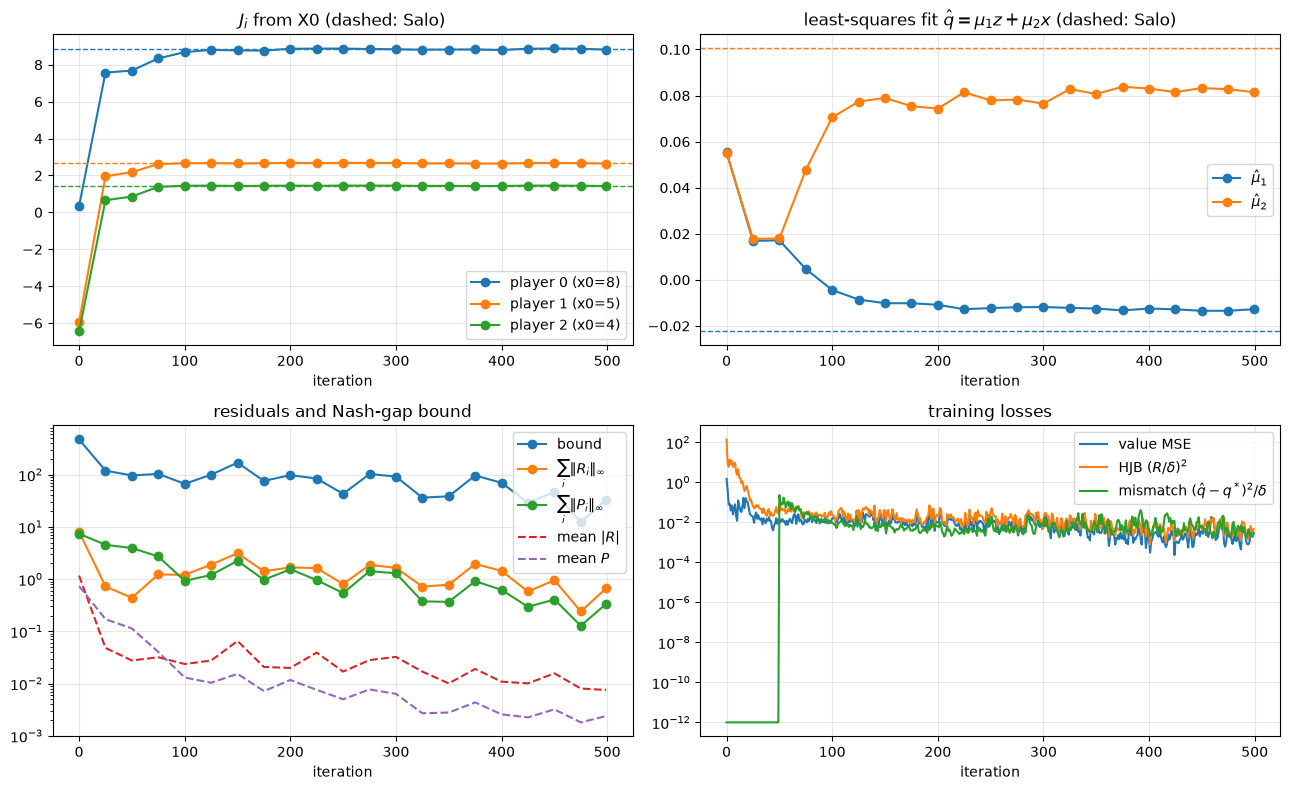

In [6]:
H = trainer.history
it = np.array([h["iteration"] for h in H])
ev = [h for h in H if "J_rl" in h]
it_ev = np.array([h["iteration"] for h in ev])

fig, ax = plt.subplots(2, 2, figsize=(13, 8))

J_rl = np.array([h["J_rl"] for h in ev])
for i in range(N_PLAYERS):
    l, = ax[0, 0].plot(it_ev, J_rl[:, i], "o-", label=f"player {i} (x0={X0[i]:.0f})")
    ax[0, 0].axhline(J_salo[i], ls="--", color=l.get_color(), lw=1)
ax[0, 0].set(title="$J_i$ from X0 (dashed: Salo)", xlabel="iteration")
ax[0, 0].legend(); ax[0, 0].grid(alpha=.3)

ax[0, 1].plot(it_ev, [h["mu1_fit"] for h in ev], "o-", label=r"$\hat\mu_1$")
ax[0, 1].plot(it_ev, [h["mu2_fit"] for h in ev], "o-", label=r"$\hat\mu_2$")
ax[0, 1].axhline(ref.mu1, ls="--", color="C0", lw=1)
ax[0, 1].axhline(ref.mu2, ls="--", color="C1", lw=1)
ax[0, 1].set(title=r"least-squares fit $\hat q = \mu_1 z + \mu_2 x$ (dashed: Salo)", xlabel="iteration")
ax[0, 1].legend(); ax[0, 1].grid(alpha=.3)

ax[1, 0].semilogy(it_ev, [h["bound"] for h in ev], "o-", label="bound")
ax[1, 0].semilogy(it_ev, [h["R_sup"] for h in ev], "o-", label=r"$\sum_i\|R_i\|_\infty$")
ax[1, 0].semilogy(it_ev, [h["P_sup"] for h in ev], "o-", label=r"$\sum_i\|P_i\|_\infty$")
ax[1, 0].semilogy(it_ev, [h["R_mean"] for h in ev], "--", label=r"mean $|R|$")
ax[1, 0].semilogy(it_ev, [h["P_mean"] for h in ev], "--", label=r"mean $P$")
ax[1, 0].set(title="residuals and Nash-gap bound", xlabel="iteration")
ax[1, 0].legend(); ax[1, 0].grid(alpha=.3)

ax[1, 1].semilogy(it, [h["value_mse"] for h in H], label="value MSE")
ax[1, 1].semilogy(it, [h["hjb"] for h in H], label=r"HJB $(R/\delta)^2$")
ax[1, 1].semilogy(it, [max(h["mismatch"], 1e-12) for h in H], label=r"mismatch $(\hat q - q^*)^2/\delta$")
ax[1, 1].set(title="training losses", xlabel="iteration")
ax[1, 1].legend(); ax[1, 1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6 — Épisode déterministe depuis X0 : DeepSet vs Salo

player 0: J_rl = 8.8181   J_salo = 8.8599   rel. err = -0.47%
player 1: J_rl = 2.6475   J_salo = 2.6600   rel. err = -0.47%
player 2: J_rl = 1.4277   J_salo = 1.4323   rel. err = -0.32%


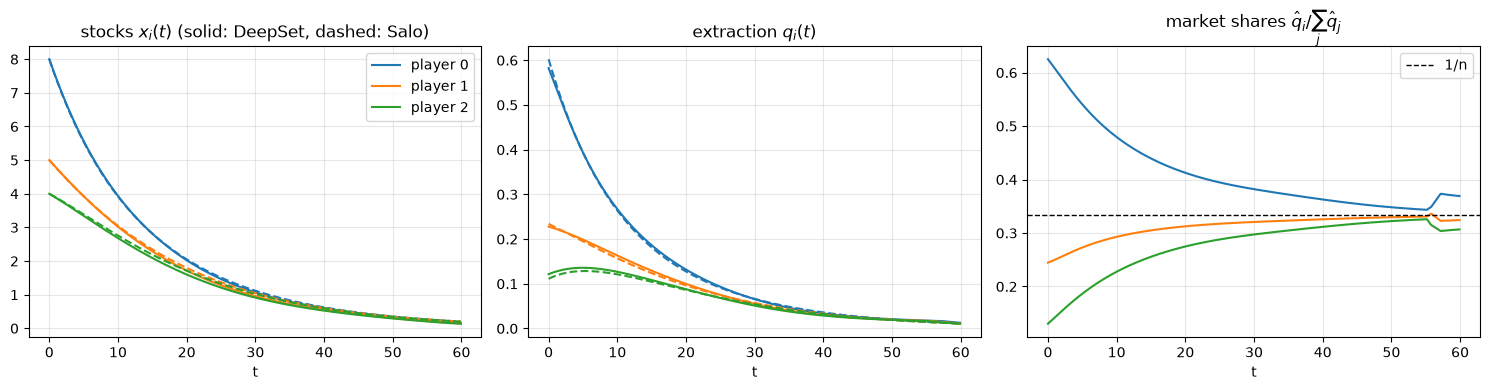

In [7]:
J_rl, X_rl, Q_rl = rollout(game, deepset_policy_fn(actor, game), X0, EVAL_STEPS)
for i in range(N_PLAYERS):
    print(f"player {i}: J_rl = {J_rl[i]:.4f}   J_salo = {J_salo[i]:.4f}   rel. err = {(J_rl[i] - J_salo[i]) / J_salo[i]:+.2%}")

ZOOM = 600
t = np.arange(EVAL_STEPS + 1) * game.dt
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i in range(N_PLAYERS):
    l, = ax[0].plot(t[:ZOOM], X_rl[:ZOOM, i], label=f"player {i}")
    ax[0].plot(t[:ZOOM], X_salo[:ZOOM, i], "--", color=l.get_color())
    ax[1].plot(t[:ZOOM], Q_rl[:ZOOM, i], color=l.get_color())
    ax[1].plot(t[:ZOOM], Q_salo[:ZOOM, i], "--", color=l.get_color())
shares_rl = Q_rl / Q_rl.sum(1, keepdims=True)
for i in range(N_PLAYERS):
    ax[2].plot(t[:ZOOM], shares_rl[:ZOOM, i])
ax[2].axhline(1 / N_PLAYERS, ls="--", color="k", lw=1, label="1/n")
ax[0].set(title="stocks $x_i(t)$ (solid: DeepSet, dashed: Salo)", xlabel="t")
ax[1].set(title="extraction $q_i(t)$", xlabel="t")
ax[2].set(title=r"market shares $\hat q_i/\sum_j \hat q_j$", xlabel="t")
for a in ax:
    a.grid(alpha=.3)
ax[0].legend(); ax[2].legend()
plt.tight_layout(); plt.show()

## 7 — Politique et valeur apprises vs Salo

Coupes à $z_i=\sum_{j\neq i}x_j$ fixé (les autres joueurs ont des stocks égaux à $z/(N-1)$) : $\hat q_0$ et $\hat V_0$ en fonction de $x_0$.

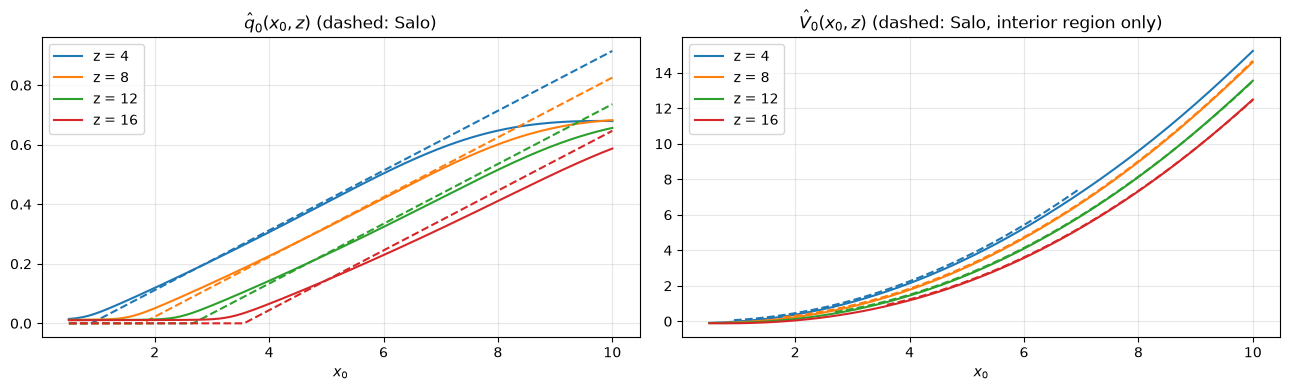

       mu1_fit = -0.01275
      mu1_salo = -0.02236
       mu2_fit = 0.08149
      mu2_salo = 0.10044
   policy_rmse = 0.02785
 value_rel_err = 0.01122
         R_sup = 0.66563
         P_sup = 0.33562
        R_mean = 0.00754
        P_mean = 0.00239
         bound = 33.33759


In [8]:
xs = torch.linspace(0.5, 10, 200)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, z in enumerate([4.0, 8.0, 12.0, 16.0]):
    xb = torch.empty(len(xs), N_PLAYERS)
    xb[:, 0] = xs
    xb[:, 1:] = z / (N_PLAYERS - 1)
    with torch.no_grad():
        q_hat = actor.mean_action(xb, game)[:, 0]
        V_hat = critic(xb)[:, 0]
    q_ref = ref.policy(xb)[:, 0]
    V_ref = ref.value(xb)[:, 0]
    inside = ref.interior_mask(xb)
    ax[0].plot(xs, q_hat, color=f"C{k}", label=f"z = {z:.0f}")
    ax[0].plot(xs, q_ref, "--", color=f"C{k}")
    ax[1].plot(xs, V_hat, color=f"C{k}", label=f"z = {z:.0f}")
    ax[1].plot(xs[inside], V_ref[inside], "--", color=f"C{k}")
ax[0].set(title=r"$\hat q_0(x_0, z)$ (dashed: Salo)", xlabel="$x_0$")
ax[1].set(title=r"$\hat V_0(x_0, z)$ (dashed: Salo, interior region only)", xlabel="$x_0$")
for a in ax:
    a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

final = evaluate(actor, critic, game, X0, EVAL_STEPS, low=cfg.x0_low, high=cfg.x0_high)
for k in ("mu1_fit", "mu1_salo", "mu2_fit", "mu2_salo", "policy_rmse", "value_rel_err",
          "R_sup", "P_sup", "R_mean", "P_mean", "bound"):
    print(f"{k:>14} = {final[k]:.5f}")

## 8 — Généralisation à d'autres $N$ (sans réentraînement)

Le même réseau est évalué sur des jeux à $N$ joueurs. Pour $N$ grand, les tirages uniformes sur $[0.5, 10]^N$ tombent rarement dans la région intérieure de Salo : on échantillonne donc des états proches de la symétrie, $x \in [4, 8]^N$.

In [9]:
print(f"{'N':>3} | {'mu1 salo':>9} {'mu1 fit':>9} | {'mu2 salo':>9} {'mu2 fit':>9} | {'J rel err':>9} | {'q rmse':>7} | {'interior':>8} | {'bound':>8}")
for n in [2, 3, 5, 10, 20]:
    g_n = game.with_n(n)
    x0_n = np.linspace(8.0, 4.0, n)
    r = evaluate(actor, critic, g_n, x0_n, EVAL_STEPS, low=4.0, high=8.0)
    print(f"{n:>3} | {r['mu1_salo']:+9.5f} {r['mu1_fit']:+9.5f} | {r['mu2_salo']:+9.5f} {r['mu2_fit']:+9.5f} | "
          f"{r['J_rel_err']:9.2%} | {r.get('policy_rmse', float('nan')):7.4f} | {r['interior_frac']:8.2f} | {r['bound']:8.3f}")

  N |  mu1 salo   mu1 fit |  mu2 salo   mu2 fit | J rel err |  q rmse | interior |    bound
  2 |  -0.02978  +0.00328 |  +0.09747  +0.09908 |    10.64% |  0.2170 |     1.00 |   50.986
  3 |  -0.02236  -0.02096 |  +0.10044  +0.09603 |     0.37% |  0.0128 |     1.00 |    1.583
  5 |  -0.01507  -0.00621 |  +0.10257  +0.03684 |    16.21% |  0.1977 |     0.99 |  199.322
 10 |  -0.00841  +0.00002 |  +0.10334  +0.00024 |    93.44% |  0.1924 |     0.29 |  646.841
 20 |  -0.00452  +0.00001 |  +0.10283  +0.00002 |    94.63% |     nan |     0.00 | 1579.203


## 9 — Nash gap empirique par meilleure réponse (optionnel, long)

On réutilise `Nash_Gap.compute_nash_gap` : pour chaque joueur, on gèle $\hat\pi$ pour les autres et on entraîne une meilleure réponse HJB-PPO. Rappel : à un vrai Nash le gap estimé est $\le 0$, et sa valeur absolue mesure l'erreur d'optimisation de la meilleure réponse (environ 0.3 sur l'équilibre de Salo).

In [ ]:
RUN_NASH_GAP = True

if RUN_NASH_GAP:
    from Nash_Gap import PPOConfig, compute_nash_gap
    from DeepSet_PPO import make_nash_gap_policy, salo_gamespec

    spec = salo_gamespec(game, max_steps=EVAL_STEPS)
    policy = make_nash_gap_policy(actor, game)
    result = compute_nash_gap(spec, [policy] * N_PLAYERS, X0,
                              ppo_config=PPOConfig(episodes=1000), verbose=True, log_every=50)
    for r in result.per_player:
        print(f"player {r.player}: J_policy={r.J_policy:.4f}  J_BR={r.J_best_response:.4f}  gap={r.gap:+.4f}")
    print(f"nash_gap (mean over players) = {result.nash_gap:+.4f}")

[Nash_Gap] training best response for player 0...
  episode    50 | discounted reward 3.5410 | J_policy=8.8236 | gap=-5.2826
  episode   100 | discounted reward 7.2068 | J_policy=8.8236 | gap=-1.6168


## 10 — Sauvegarde

In [11]:
trainer.save("deepset_salo_N3.pt")
# reload: trainer = SharedPPOTrainer(game, cfg); trainer.load("deepset_salo_N3.pt")